# CAN Bus Security and Intrusion Detection

**Module 05 · Cybersecurity (ISO/SAE 21434)** · Notebook 4 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/05_Cybersecurity_ISO21434/04_can_bus_intrusion_detection.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [TARA](02_tara.ipynb), [Attack surface analysis](03_attack_surface_analysis.ipynb) | ISO/SAE 21434:2021, UN R155, ISO 11898-1:2024, AUTOSAR SecOC |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After working through this notebook you will be able to:

1. Explain the CAN 2.0 frame format, bitwise arbitration and the three properties that make the bus hard to defend: **broadcast**, **priority by identifier** and **no sender authentication**.
2. Load and inspect **real in-vehicle CAN traffic with physically verified attacks** (the ROAD dataset of Oak Ridge National Laboratory) and reconstruct frame-level ground truth from the published metadata.
3. Implement and tune four intrusion detectors — **per-identifier frequency**, **identifier entropy**, **signal-level payload plausibility** and a **learned window classifier** — on benign training traffic only, or with an honest capture-level split.
4. Evaluate them per attack type (fuzzing, targeted injection, masquerade) the way a vehicle programme must: **detection rate, detection delay and false alarms per hour**, including a confidence bound when no false alarm is observed.
5. Quantify the cost of prevention with AUTOSAR SecOC on the real bus, and answer the questions an ISO/SAE 21434 / UN R155 reviewer asks about an intrusion-detection claim.

> **Scope and intent.** This is defensive teaching material. The attacks analysed here were executed by the dataset authors on their own vehicle and are published for benchmarking detectors. Nothing here targets a vehicle, and no step needs one.

## 1. Setup

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety import iso21434 as S

import os
os.environ.setdefault("OMP_NUM_THREADS", "2")            # keep scikit-learn polite on shared CPUs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import chi2
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
BYTES = [f"b{k}" for k in range(8)]
BITRATE = 500_000      # bit/s, assumed for bus-load arithmetic (ROAD does not publish the bit rate)

## 2. CAN in one page: frame, arbitration and why it is hard to secure


Classic CAN (CAN 2.0A, now specified in ISO 11898-1:2024) is a **multi-master broadcast bus**. A base data frame with an
11-bit identifier contains:

| Field | Bits | Purpose |
|---|---|---|
| SOF | 1 | start of frame (dominant) |
| Identifier | 11 | **message identity and priority** — not a sender address |
| RTR, IDE, r0 | 3 | frame-type flags |
| DLC | 4 | data length code (0–8 bytes) |
| Data | 0–64 | payload (signals packed by the OEM's communication matrix) |
| CRC + delimiter | 16 | 15-bit CRC protects against *random* errors only |
| ACK slot + delimiter | 2 | any receiver acknowledges |
| EOF + IFS | 7 + 3 | end of frame, inter-frame space |

Before bit stuffing a frame with $s$ data bytes has $47 + 8s$ bits. Because the controller inserts a stuff bit after
five equal bits, the **worst-case** length used in schedulability analysis (Davis et al., 2007) is

$$C(s) = \left(g + 8s + 13 + \left\lfloor \frac{g + 8s - 1}{4} \right\rfloor\right)\tau_{\mathrm{bit}}, \qquad g = 34 \text{ for 11-bit identifiers.}$$

**Arbitration.** Nodes that wish to send start together and transmit their identifier bit by bit. The bus is a
wired-AND: a dominant `0` overwrites a recessive `1`. A node that sends `1` but reads back `0` has lost and backs off.
Hence **the lowest identifier wins**.

Three properties follow, and they are the root cause of every CAN threat:

1. **Broadcast** — every node sees every frame, so traffic can be observed passively.
2. **Priority by identifier** — a node that keeps sending low identifiers can starve the bus.
3. **No sender authentication** — any node may emit any identifier; a receiver cannot tell which ECU sent a frame.

In [2]:
def can_frame_bits(dlc, worst_case=True):
    """Bits on the wire for a classic CAN base frame (11-bit ID) incl. 3-bit IFS (Davis et al., 2007)."""
    g = 34
    bits = g + 8 * dlc + 13
    if worst_case:
        bits += (g + 8 * dlc - 1) // 4
    return bits

for dlc in (0, 4, 8):
    nom, wc = can_frame_bits(dlc, False), can_frame_bits(dlc, True)
    print(f"DLC={dlc}: {nom:3d} bits nominal, {wc:3d} bits worst case "
          f"-> {wc / BITRATE * 1e3:.3f} ms at {BITRATE // 1000} kbit/s")
FRAME_TIME = can_frame_bits(8) / BITRATE   # every frame in our simulation carries 8 data bytes

DLC=0:  47 bits nominal,  55 bits worst case -> 0.110 ms at 500 kbit/s
DLC=4:  79 bits nominal,  95 bits worst case -> 0.190 ms at 500 kbit/s
DLC=8: 111 bits nominal, 135 bits worst case -> 0.270 ms at 500 kbit/s


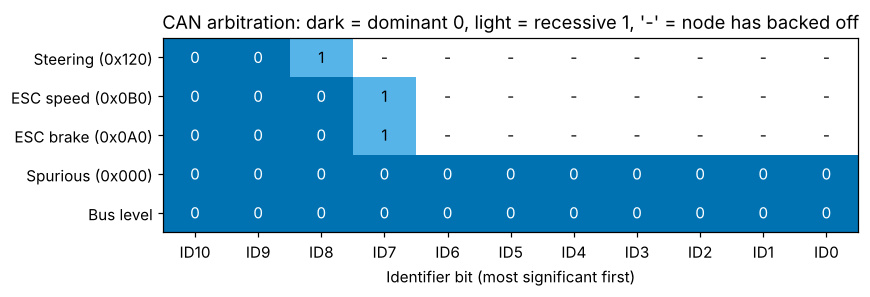

Steering (0x120)     loses at identifier bit 8
ESC speed (0x0B0)    loses at identifier bit 7
ESC brake (0x0A0)    loses at identifier bit 7
Spurious (0x000)     WINS arbitration

The lowest identifier always wins the bus: a node emitting 0x000 would dominate it.


In [3]:
def arbitrate(ids, width=11):
    """Bitwise CAN arbitration. Returns bit matrix, bus level per bit, bit index where each node lost, winner."""
    bits = np.array([[(i >> (width - 1 - b)) & 1 for b in range(width)] for i in ids])
    active = np.ones(len(ids), bool)
    lost_at = np.full(len(ids), -1)
    bus = []
    for b in range(width):
        level = bits[active, b].min()                  # wired-AND: dominant 0 wins
        bus.append(level)
        losers = active & (bits[:, b] != level)
        lost_at[losers] = b
        active &= ~losers
    return bits, np.array(bus), lost_at, int(np.flatnonzero(active)[0])

contenders = {"Steering (0x120)": 0x120, "ESC speed (0x0B0)": 0x0B0, "ESC brake (0x0A0)": 0x0A0, "Spurious (0x000)": 0x000}
bits, bus, lost_at, winner = arbitrate(list(contenders.values()))

grid = np.vstack([bits, bus]).astype(float)
for r, b in enumerate(lost_at):
    if b >= 0:
        grid[r, b + 1:] = np.nan                        # node stops driving the bus after losing
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.imshow(np.ma.masked_invalid(grid), cmap=ListedColormap([OKABE_ITO[4], OKABE_ITO[1]]), aspect="auto")
for (r, c), v in np.ndenumerate(grid):
    ax.text(c, r, "-" if np.isnan(v) else int(v), ha="center", va="center", color="white" if v == 0 else "black")
ax.set_yticks(range(len(contenders) + 1), list(contenders) + ["Bus level"])
ax.set_xticks(range(11), [f"ID{10 - b}" for b in range(11)])
ax.set_xlabel("Identifier bit (most significant first)")
ax.set_title("CAN arbitration: dark = dominant 0, light = recessive 1, '-' = node has backed off")
ax.grid(False)
plt.tight_layout(); plt.show()
for n, b in zip(contenders, lost_at):
    print(f"{n:20s} " + ("WINS arbitration" if b < 0 else f"loses at identifier bit {10 - b}"))
print("\nThe lowest identifier always wins the bus: a node emitting 0x000 would dominate it.")

## 3. The data: ROAD, a real CAN capture with verified attacks

**Choice of dataset.** Three open candidates were checked (as of October 2026):

| Dataset | Content | Access | Licence | Decision |
|---|---|---|---|---|
| **ROAD** (Verma et al., 2024; Oak Ridge National Laboratory) | 12 ambient captures (~3 h) and 33 attack captures (~30 min) from one mid-2010s vehicle, mostly on a dynamometer; fuzzing, targeted injection, masquerade; effects physically verified | Zenodo record 10462796, one 557 MB zip, no login | **CC BY 4.0** | **used** |
| HCRL Car-Hacking (Song et al., 2020) | DoS, fuzzing, gear/RPM spoofing via OBD-II | Dropbox links | no licence stated; "for academic purposes" | not used: terms do not clearly permit redistribution in an open course |
| Synthetic traffic | any attack you can imagine | — | — | replaced: ground truth is perfect but realism is not |

The loader `D.can_ids(...)` reads **single capture files** out of the Zenodo archive by HTTP range requests, so only the
logs used here (about 56 MB compressed) are downloaded, once, and cached. Labels are reconstructed from each capture's
`capture_metadata.json`: a frame is *injected* when it lies inside the published injection interval, carries the
injected identifier (any identifier for fuzzing) and matches the published payload pattern (`X` = byte left unchanged).

**What ROAD is and is not.** Identifiers, timestamps and payloads were obfuscated by the authors so the vehicle cannot be
identified; signal meanings in this notebook come from the paper's attack descriptions, not from a DBC we own. The
*masquerade* variants are produced in post-processing by removing the genuine target-ID frame that precedes each
injected frame — a simulated masquerade on top of a real injection. The "accelerator" captures contain no injected
frames (the exploit itself was withheld) and cannot be labelled at frame level, so they are not used.

In [4]:
ATTACKS = {
    "fuzzing": ["fuzzing_attack_1", "fuzzing_attack_2", "fuzzing_attack_3"],
    "targeted injection": ["correlated_signal_attack_1", "correlated_signal_attack_2", "correlated_signal_attack_3",
                           "max_speedometer_attack_1", "max_speedometer_attack_2", "max_speedometer_attack_3",
                           "max_engine_coolant_temp_attack", "reverse_light_on_attack_1", "reverse_light_off_attack_1"],
}
ATTACKS["masquerade"] = [c + "_masquerade" for c in ATTACKS["targeted injection"]]
TRAIN_BENIGN = ["ambient_dyno_drive_extended_long", "ambient_dyno_drive_basic_short"]
HOLDOUT_BENIGN = ["ambient_dyno_drive_extended_short", "ambient_dyno_drive_benign_anomaly",
                  "ambient_highway_street_driving_diagnostics"]
ATTACK_CAPTURES = [c for caps in ATTACKS.values() for c in caps]

def load(captures):
    # One capture at a time; the hex payload string is only needed for labelling, so drop it to save memory.
    return pd.concat([D.can_ids(c).drop(columns="data") for c in captures], ignore_index=True)

train = load(TRAIN_BENIGN)
hold = load(HOLDOUT_BENIGN)
att = load(ATTACK_CAPTURES)
META = {**D.road_metadata("attacks"), **D.road_metadata("ambient")}
print(D.attribution("ROAD"))

def describe(df):
    g = df.groupby("capture", sort=False)
    out = pd.DataFrame({"attack": g.attack.first(), "duration_s": g.t.max().round(1), "frames": g.size(),
                        "frames_per_s": (g.size() / g.t.max()).round(0), "identifiers": g.can_id.nunique(),
                        "injected_frames": g.label.sum()})
    out["on_dyno"] = [META[c]["on_dyno"] for c in out.index]
    return out

overview = pd.concat([describe(train).assign(role="train (benign)"), describe(hold).assign(role="held-out benign"),
                      describe(att).assign(role="attack")])
print(overview.to_string())
minutes = overview.groupby("role").duration_s.sum() / 60
print(f"\nBenign training {minutes['train (benign)']:.1f} min, "
      f"held-out benign {minutes['held-out benign']:.1f} min, "
      f"{len(ATTACK_CAPTURES)} attack captures.")

Data: ROAD CAN intrusion dataset, Oak Ridge National Laboratory (Verma et al., PLOS ONE 2024, doi:10.1371/journal.pone.0296879), CC BY 4.0, https://doi.org/10.5281/zenodo.10462796


                                                        attack  duration_s   frames  frames_per_s  identifiers  injected_frames  on_dyno             role
capture                                                                                                                                                  
ambient_dyno_drive_extended_long                          none       657.9  1424208        2165.0          106                0     True   train (benign)
ambient_dyno_drive_basic_short                            none       444.8  1063624        2392.0          106                0     True   train (benign)
ambient_dyno_drive_extended_short                         none       359.8   790442        2197.0          106                0     True  held-out benign
ambient_dyno_drive_benign_anomaly                         none       456.5   771519        1690.0          106                0     True  held-out benign
ambient_highway_street_driving_diagnostics                none       469.9  

**Look at the real bus first.** Two things matter for every detector below: most identifiers are strictly periodic
(10 ms to 1 s), and the per-frame **jitter is of the order of a millisecond** — far larger than in idealised
simulations. A rule that is tight on a simulated bus fires constantly on a real one.

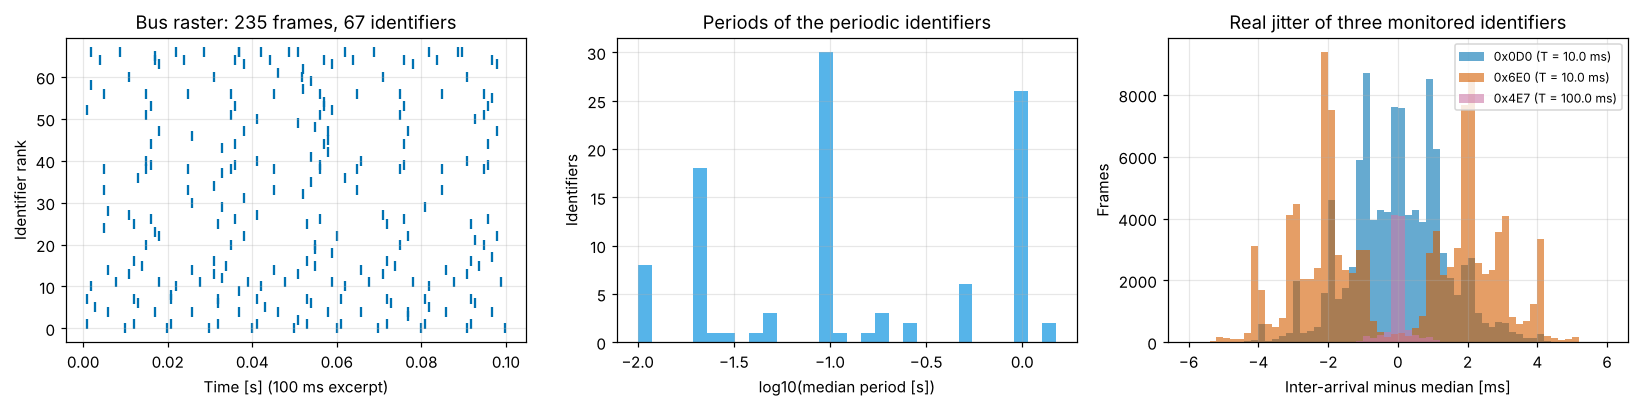

103 of 106 identifiers are periodic; for the 26 identifiers with a 10-20 ms period the 10-90 % spread of the inter-arrival time is 1.6 ms (median).
2256 frames/s with mean worst-case length 135 bits -> 61% bus load if the bus runs at 500 kbit/s (assumed).


In [5]:
def add_gaps(df):
    gap = np.full(len(df), np.nan)
    t = df.t.to_numpy()
    for idx in df.groupby(["capture", "can_id"]).indices.values():
        gap[idx[1:]] = np.diff(t[idx])
    df["gap"] = gap

for df in (train, hold, att):
    add_gaps(df)

per_id = train.groupby("can_id").gap.agg(period="median", q10=lambda x: x.quantile(0.10),
                                         q90=lambda x: x.quantile(0.90), jitter_sd="std", n="count")
per_id["periodic"] = ((per_id.q90 - per_id.q10) / per_id.period < 1.0) & (per_id.n >= 50)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axes[0]
win = train[(train.capture == TRAIN_BENIGN[0]) & (train.t > 100) & (train.t < 100.1)]
ids_sorted = sorted(win.can_id.unique())
ax.scatter(win.t - 100, [ids_sorted.index(c) for c in win.can_id], marker="|", s=40, color=OKABE_ITO[4])
ax.set_xlabel("Time [s] (100 ms excerpt)"); ax.set_ylabel("Identifier rank"); ax.set_title(f"Bus raster: {len(win)} frames, {len(ids_sorted)} identifiers")
ax = axes[1]
ax.hist(np.log10(per_id.period[per_id.periodic]), bins=30, color=OKABE_ITO[1])
ax.set_xlabel("log10(median period [s])"); ax.set_ylabel("Identifiers"); ax.set_title("Periods of the periodic identifiers")
ax = axes[2]
for c, col in zip([0x0D0, 0x6E0, 0x4E7], OKABE_ITO[4:7]):
    g = train.gap[(train.can_id == c)].dropna() * 1e3
    ax.hist(g - g.median(), bins=np.linspace(-6, 6, 61), alpha=0.6, color=col, label=f"0x{c:03X} (T = {g.median():.1f} ms)")
ax.set_xlabel("Inter-arrival minus median [ms]"); ax.set_ylabel("Frames"); ax.set_title("Real jitter of three monitored identifiers")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

dlc_bits = can_frame_bits(train.dlc.to_numpy().astype(int)).mean()
rate = len(train) / train.groupby("capture").t.max().sum()
fast = per_id[per_id.periodic & (per_id.period < 0.025)]
print(f"{per_id.periodic.sum()} of {len(per_id)} identifiers are periodic; for the {len(fast)} identifiers with a 10-20 ms "
      f"period the 10-90 % spread of the inter-arrival time is {((fast.q90 - fast.q10) * 1e3).median():.1f} ms (median).")
print(f"{rate:.0f} frames/s with mean worst-case length {dlc_bits:.0f} bits -> {rate * dlc_bits / BITRATE:.0%} bus load "
      f"if the bus runs at {BITRATE // 1000} kbit/s (assumed).")

### What the attacks look like on the wire

The same *maximum speedometer* attack, once as a real **targeted injection** (genuine and forged `0x0D0` frames
interleaved) and once in its **masquerade** variant (the genuine frames removed). The injection doubles the frame rate of
the identifier; the masquerade keeps the rate and changes only the content. This single picture explains most of the
results that follow.

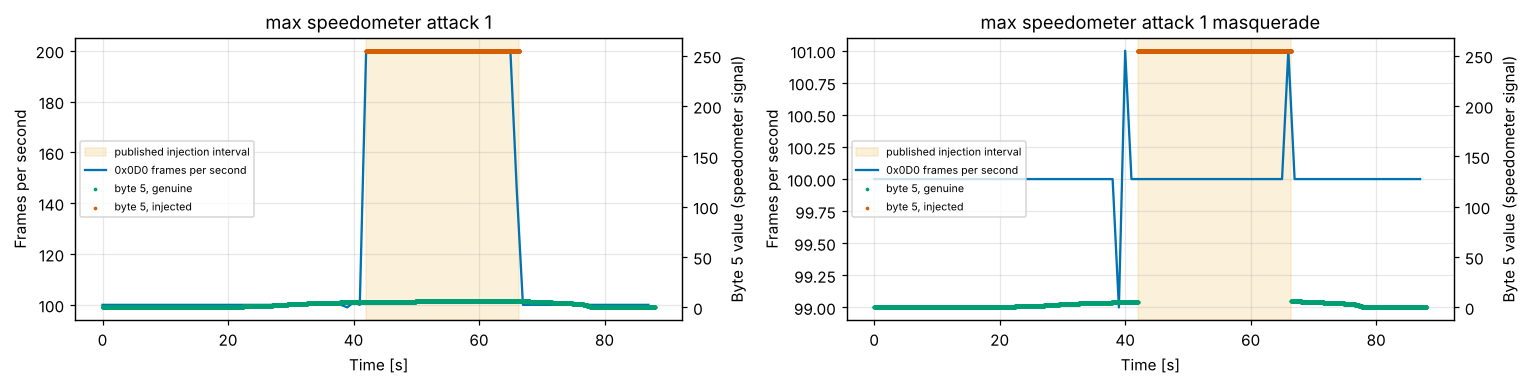

max_speedometer_attack_1               0x0D0 rate before 100.0 Hz, during 200.0 Hz; injected frames 2445
max_speedometer_attack_1_masquerade    0x0D0 rate before 100.0 Hz, during 100.0 Hz; injected frames 2445


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=False)
for ax, cap in zip(axes, ["max_speedometer_attack_1", "max_speedometer_attack_1_masquerade"]):
    d = att[(att.capture == cap) & (att.can_id == 0x0D0)]
    lo, hi = META[cap]["injection_interval"]
    ax.axvspan(lo, hi, color=OKABE_ITO[0], alpha=0.15, label="published injection interval")
    rate_hz = d.groupby(np.floor(d.t)).size().iloc[:-1]          # drop the incomplete last second
    ax.plot(rate_hz.index, rate_hz.to_numpy(), color=OKABE_ITO[4], lw=1.5, label="0x0D0 frames per second")
    ax2 = ax.twinx()
    ax2.scatter(d.t[d.label == 0], d.b5[d.label == 0], s=2, color=OKABE_ITO[2], label="byte 5, genuine")
    ax2.scatter(d.t[d.label == 1], d.b5[d.label == 1], s=2, color=OKABE_ITO[5], label="byte 5, injected")
    ax2.set_ylabel("Byte 5 value (speedometer signal)"); ax2.grid(False)
    ax.set_xlabel("Time [s]"); ax.set_ylabel("Frames per second"); ax.set_title(cap.replace("_", " "))
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="center left")
plt.tight_layout(); plt.show()
for cap in ["max_speedometer_attack_1", "max_speedometer_attack_1_masquerade"]:
    d = att[(att.capture == cap) & (att.can_id == 0x0D0)]
    lo, hi = META[cap]["injection_interval"]
    inside = (d.t >= lo) & (d.t <= hi)
    print(f"{cap:38s} 0x0D0 rate before {(~inside & (d.t < lo)).sum() / lo:5.1f} Hz, "
          f"during {inside.sum() / (hi - lo):5.1f} Hz; injected frames {d.label.sum()}")

## 4. Evaluation protocol

Detectors are fitted on **benign data only** (two ambient dynamometer captures, about 18 minutes). They are then tested
on data they have never seen:

* **Attack captures** (21): an attack is *detected* if at least one alarm is raised inside the published injection
  interval; the **detection delay** is the time from the start of the injection to that first alarm.
* **False alarms** are counted as *alarm events* (alarms closer than 1 s merged into one event, which is what a
  security-operations analyst sees) on held-out benign traffic: three unseen ambient captures, including a real on-road
  drive and a capture in which the driver deliberately provoked *benign* anomalies (doors, seat belt), plus the
  pre-injection part of every attack capture. Rates are extrapolated to **false alarms per hour**.
* With only tens of minutes of benign data, "no false alarm observed" does **not** mean a rate of zero. We report the
  exact one-sided 95 % Poisson upper bound; with zero events in $T$ hours it is $3.0/T$ (the "rule of three").

Detectors decide on non-overlapping **100 ms windows** unless stated; an alarm is time-stamped at the end of its window,
which is when an on-board monitor could actually raise it.

In [7]:
WIN = 0.1           # s, decision window
MERGE = 1.0         # s, alarms closer than this form one event
TOL = 1e-3          # s, the published interval bounds are rounded; the first forged frame can sit on the bound

def win_index(df):
    return np.floor(df.t.to_numpy() / WIN).astype(np.int64)

def alarms_from_windows(df, flagged):
    # flagged: boolean Series indexed by (capture, win) -> dict capture -> alarm times [s]
    out = {}
    for (cap, w) in flagged[flagged].index:
        out.setdefault(cap, []).append((w + 1) * WIN)
    return {c: np.sort(v) for c, v in out.items()}

def alarms_from_frames(df, mask):
    sel = df[mask]
    return {c: g.t.to_numpy() for c, g in sel.groupby("capture")}

def n_events(times):
    times = np.sort(np.asarray(times))
    return 0 if len(times) == 0 else 1 + int(np.sum(np.diff(times) > MERGE))

def poisson_upper(n, hours, conf=0.95):
    return chi2.ppf(conf, 2 * (n + 1)) / 2 / hours

def evaluate(name, alarms_att, alarms_hold, attacks=None):
    rows, ev, hours = [], 0, 0.0
    for fam, caps in (attacks or ATTACKS).items():
        for cap in caps:
            lo, hi = META[cap]["injection_interval"]
            a = alarms_att.get(cap, np.array([]))
            hit = a[(a >= lo - TOL) & (a <= hi + WIN)]
            pre = a[a < lo - TOL]
            ev += n_events(pre); hours += (lo - TOL) / 3600
            rows.append(dict(detector=name, family=fam, capture=cap, detected=len(hit) > 0,
                             delay_ms=max(hit[0] - lo, 0.0) * 1e3 if len(hit) else np.nan))
    for cap in HOLDOUT_BENIGN:
        ev += n_events(alarms_hold.get(cap, [])); hours += hold.t[hold.capture == cap].max() / 3600
    per_capture = pd.DataFrame(rows)
    summary = per_capture.groupby("family", sort=False).agg(detected=("detected", "mean"),
                                                            median_delay_ms=("delay_ms", "median"))
    summary.insert(0, "detector", name)
    summary["fa_events"] = ev
    summary["fa_per_h"] = ev / hours
    summary["fa_per_h_95up"] = poisson_upper(ev, hours)
    return per_capture, summary

BENIGN_HOURS = (sum(META[c]["injection_interval"][0] for c in ATTACK_CAPTURES)
                + sum(hold.t[hold.capture == c].max() for c in HOLDOUT_BENIGN)) / 3600
print(f"Benign test exposure: {BENIGN_HOURS * 60:.1f} min -> zero false alarms would still allow up to "
      f"{poisson_upper(0, BENIGN_HOURS):.1f} per hour (95 % upper bound).")

Benign test exposure: 26.6 min -> zero false alarms would still allow up to 6.8 per hour (95 % upper bound).


## 5. Detector (a): per-identifier frequency

The oldest and cheapest idea (Song et al., 2016): a periodic identifier arrives at a near-constant rate, so an injection
on that identifier **raises its frame count**. We learn, per periodic identifier, the largest number of frames seen in
any 100 ms window of benign training traffic, and flag a window in which the count is exceeded. Any identifier never
seen in training is flagged at once (fuzzing).

Because of real jitter, a single window with one extra frame is not rare. The engineering knob is **persistence**: require
the excess to last for $P$ consecutive windows. Larger $P$ buys fewer false alarms with detection delay — the trade-off a
programme has to set against the fault-tolerant time interval of the affected safety goal.

In [8]:
def window_counts(df):
    return df.assign(win=win_index(df)).groupby(["capture", "win", "can_id"]).size()

max_count = window_counts(train).groupby(level="can_id").max()
PERIODIC = set(per_id.index[per_id.periodic])

def frequency_alarms(df, persist=1):
    cnt = window_counts(df)
    ids = cnt.index.get_level_values("can_id")
    limit = ids.map(max_count).to_numpy(dtype=float)
    unknown = pd.Series(np.isnan(limit), index=cnt.index).groupby(level=[0, 1]).any()
    over = pd.Series(ids.isin(PERIODIC) & (cnt.to_numpy() > np.nan_to_num(limit, nan=np.inf)), index=cnt.index)
    over = over.unstack("can_id", fill_value=False)
    if persist > 1:   # excess on the same identifier in P consecutive windows of the same capture
        over = over.groupby(level=0, group_keys=False).apply(
            lambda x: x.astype(int).rolling(persist, min_periods=persist).sum() >= persist)
    flagged = over.any(axis=1).reindex(unknown.index, fill_value=False) | unknown
    return alarms_from_windows(df, flagged)

freq_rows = []
for P in (1, 2, 3):
    pc, sm = evaluate(f"frequency, P={P}", frequency_alarms(att, P), frequency_alarms(hold, P))
    freq_rows.append(sm)
    if P == 2:
        pc_freq, sm_freq = pc, sm
freq_table = pd.concat(freq_rows)
print(freq_table.round(2).to_string())

                          detector  detected  median_delay_ms  fa_events  fa_per_h  fa_per_h_95up
family                                                                                           
fuzzing             frequency, P=1      1.00            75.55         62    140.04         173.02
targeted injection  frequency, P=1      1.00            72.08         62    140.04         173.02
masquerade          frequency, P=1      0.33           290.80         62    140.04         173.02
fuzzing             frequency, P=2      1.00            75.55          0      0.00           6.77
targeted injection  frequency, P=2      1.00           172.08          0      0.00           6.77
masquerade          frequency, P=2      0.00              NaN          0      0.00           6.77
fuzzing             frequency, P=3      1.00            75.55          0      0.00           6.77
targeted injection  frequency, P=3      1.00           281.52          0      0.00           6.77
masquerade          

Fuzzing is caught by the unknown-identifier rule within one window. Targeted injection on a periodic identifier is caught
as soon as the excess persists. The **masquerade is invisible**: the frame rate does not change, by construction. The
persistence knob moves false alarms against delay exactly as expected; $P = 2$ (200 ms of evidence) is used as the
operating point below.

## 6. Detector (b): identifier entropy

Müter and Asaj (2011): the Shannon entropy of the identifier distribution in a window, $H = -\sum_m p_m \log_2 p_m$, is
stable in normal traffic; fuzzing (many rare identifiers) raises it and a flood on one identifier lowers it. One statistic,
no per-identifier model — attractive for a resource-constrained ECU, but it sees only the *mix* of identifiers.

A mean ± 4σ band does not work on the real bus: the benign entropy distribution has a long lower tail (phases with the
engine off and fewer senders active), which inflates σ. We use the **benign envelope** instead — alarm when a window's
entropy leaves the [min, max] range seen in training — with the same two-window persistence as above.

In [9]:
def window_entropy(df):
    cnt = window_counts(df)
    p = cnt / cnt.groupby(level=[0, 1]).transform("sum")
    return (-(p * np.log2(p))).groupby(level=[0, 1]).sum()

H_train = window_entropy(train)
H_LO, H_HI = H_train.min(), H_train.max()

def entropy_alarms(df, persist=2):
    out = (window_entropy(df) < H_LO) | (window_entropy(df) > H_HI)
    out = out.groupby(level=0, group_keys=False).apply(lambda x: x.astype(int).rolling(persist, min_periods=persist).sum() >= persist)
    return alarms_from_windows(df, out)

pc_ent, sm_ent = evaluate("ID entropy envelope", entropy_alarms(att), entropy_alarms(hold))
print(f"Benign training entropy per 100 ms window: median {H_train.median():.2f} bits, 0.1 % quantile "
      f"{H_train.quantile(0.001):.2f}, envelope [{H_LO:.2f}, {H_HI:.2f}]")
fz = window_entropy(att).loc["fuzzing_attack_1"]
lo, hi = META["fuzzing_attack_1"]["injection_interval"]
print(f"fuzzing_attack_1: entropy {fz[(fz.index * WIN >= lo) & (fz.index * WIN <= hi)].mean():.2f} bits during the attack "
      f"vs {fz[fz.index * WIN < lo].mean():.2f} before")
print(sm_ent.round(2).to_string())

Benign training entropy per 100 ms window: median 5.56 bits, 0.1 % quantile 2.77, envelope [2.58, 5.70]


fuzzing_attack_1: entropy 5.81 bits during the attack vs 5.58 before
                               detector  detected  median_delay_ms  fa_events  fa_per_h  fa_per_h_95up
family                                                                                                
fuzzing             ID entropy envelope       1.0           177.03          0       0.0           6.77
targeted injection  ID entropy envelope       0.0              NaN          0       0.0           6.77
masquerade          ID entropy envelope       0.0              NaN          0       0.0           6.77


## 7. Detector (c): signal-level payload plausibility

Timing cannot see a masquerade; only the **content** can. Plausibility rules need to know what a byte *means*. In a
vehicle programme that knowledge comes from the communication matrix (DBC/ARXML); ROAD's identifiers are obfuscated, so we
use the signals that the dataset paper documents for its attacks and that a TARA would mark as safety- or
driver-relevant:

| Identifier | Signal (per Verma et al., 2024) | Rule learned on benign traffic |
|---|---|---|
| `0x6E0` | four wheel speeds, 2 bytes each | **cross-signal consistency**: spread between the four wheels |
| `0x0D0` byte 5 | speedometer value | **range** and **rate of change** per frame |
| `0x4E7` byte 5 | engine coolant temperature | **range** and **rate of change** per frame |
| `0x0D0` (one bit in byte 2) | reverse light | none possible without the gear signal: a valid on/off value is plausible in isolation |

Thresholds are the benign maximum with a margin (×1.5 for ranges, ×4 for rates and spreads), which a reviewer would expect
to see justified by physics and by coverage of the operating conditions.

In [10]:
WHEEL, SPEEDO, COOLANT = 0x6E0, 0x0D0, 0x4E7

def wheel_speeds(df):
    m = (df.can_id == WHEEL).to_numpy()
    p = df.loc[m, BYTES].to_numpy().astype(int)
    return np.flatnonzero(m), p[:, 0::2] * 256 + p[:, 1::2]

def signal(df, cid, byte):
    idx = np.flatnonzero((df.can_id == cid).to_numpy())
    v = df[byte].to_numpy()[idx].astype(float)
    dv = np.r_[0.0, np.abs(np.diff(v))]
    cap = df.capture.to_numpy()[idx]
    dv[np.r_[True, cap[1:] != cap[:-1]]] = 0.0
    return idx, v, dv

_, w = wheel_speeds(train)
LIM = {"wheel_spread": 4 * (w.max(1) - w.min(1)).max()}
for name, (cid, b) in {"speedo": (SPEEDO, "b5"), "coolant": (COOLANT, "b5")}.items():
    _, v, dv = signal(train, cid, b)
    LIM[name] = (v.min() / 1.5, v.max() * 1.5, 4 * max(dv.max(), 1.0))
print("Learned limits:", {k: np.round(v, 1) for k, v in LIM.items()})

def payload_alarms(df):
    flag = np.zeros(len(df), bool)
    idx, w = wheel_speeds(df)
    flag[idx] |= (w.max(1) - w.min(1)) > LIM["wheel_spread"]
    for name, (cid, b) in {"speedo": (SPEEDO, "b5"), "coolant": (COOLANT, "b5")}.items():
        idx, v, dv = signal(df, cid, b)
        lo, hi, rate = LIM[name]
        flag[idx] |= (v < lo) | (v > hi) | (dv > rate)
    return alarms_from_frames(df, flag)

pc_pay, sm_pay = evaluate("payload plausibility", payload_alarms(att), payload_alarms(hold))
print(sm_pay.round(2).to_string())
print(pc_pay[["capture", "detected", "delay_ms"]].to_string(index=False))

Learned limits: {'wheel_spread': np.int64(620), 'speedo': array([ 0., 66.,  4.]), 'coolant': array([ 81.3, 210. ,   4. ])}


                                detector  detected  median_delay_ms  fa_events  fa_per_h  fa_per_h_95up
family                                                                                                 
fuzzing             payload plausibility      0.67          1905.44          1      2.26          10.72
targeted injection  payload plausibility      0.78             0.00          1      2.26          10.72
masquerade          payload plausibility      0.78             0.00          1      2.26          10.72
                                  capture  detected    delay_ms
                         fuzzing_attack_1      True 1906.002036
                         fuzzing_attack_2      True 1904.882998
                         fuzzing_attack_3     False         NaN
               correlated_signal_attack_1      True    0.000020
               correlated_signal_attack_2      True    0.000000
               correlated_signal_attack_3      True    0.000041
                 max_speedometer

The payload rules catch the wheel-speed, speedometer and coolant attacks **in both the injection and the masquerade
variant**, within one frame period, because the forged values are physically implausible. They are blind to the reverse
light: forcing a valid on/off value is only detectable against *context* (is reverse gear engaged?), which needs a second
signal and therefore knowledge of the communication matrix. The fuzzing captures are flagged only incidentally, when an
all-`0xFF` fuzzing frame happens to carry a monitored identifier. The single false alarm on benign traffic comes from the
capture in which the driver provoked benign anomalies: the coolant value stepped by more than the rate limit. Payload rules
are only as good as the signal knowledge and the coverage of the benign data used to set their limits.

## 8. Detector (d): a learned window classifier

A supervised classifier can combine weak cues. Each 100 ms window is described by five content-agnostic features —
identifier entropy, number of unknown identifiers, the largest frame-count ratio of any periodic identifier against its
benign maximum, the number of identifiers present, and the fraction of `0xFF` payload bytes — and a gradient-boosted tree
ensemble (scikit-learn `HistGradientBoostingClassifier`) is trained on labelled windows.

**The split matters more than the model.** Windows of one capture are strongly correlated, so a random window-level split
leaks the test capture into training and reports optimistic numbers. We split **by capture**: train on the benign
training drives plus *instance 1* of the fuzzing, wheel-speed and speedometer attacks (both variants); test on instances
2 and 3, on the coolant and reverse-light attacks it has **never seen**, and on the held-out benign captures.

In [11]:
def window_features(df):
    cnt = window_counts(df)
    ids = cnt.index.get_level_values("can_id")
    limit = ids.map(max_count).to_numpy(dtype=float)
    ratio = np.where(ids.isin(PERIODIC), cnt.to_numpy() / np.nan_to_num(limit, nan=1.0), 0.0)
    d = df.assign(win=win_index(df))
    F = pd.DataFrame({
        "id_entropy": window_entropy(df),
        "unknown_ids": pd.Series(np.isnan(limit), index=cnt.index).groupby(level=[0, 1]).sum(),
        "max_rate_ratio": pd.Series(ratio, index=cnt.index).groupby(level=[0, 1]).max(),
        "n_ids": cnt.groupby(level=[0, 1]).size(),
    })
    F["frac_ff"] = (d[BYTES] == 255).mean(axis=1).groupby([d.capture, d.win]).mean()
    F["label"] = d.groupby(["capture", "win"]).label.max()
    return F

FEATURES = ["id_entropy", "unknown_ids", "max_rate_ratio", "n_ids", "frac_ff"]
TRAIN_ATTACKS = ["fuzzing_attack_1", "correlated_signal_attack_1", "correlated_signal_attack_1_masquerade",
                 "max_speedometer_attack_1", "max_speedometer_attack_1_masquerade"]
F_train, F_hold, F_att = window_features(train), window_features(hold), window_features(att)
X_fit = pd.concat([F_train, F_att.loc[TRAIN_ATTACKS]])
clf = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)
clf.fit(X_fit[FEATURES], X_fit.label)

def learned_alarms(F, thr=0.5):
    return alarms_from_windows(None, pd.Series(clf.predict_proba(F[FEATURES])[:, 1] > thr, index=F.index))

TEST = {fam: [c for c in caps if c not in TRAIN_ATTACKS] for fam, caps in ATTACKS.items()}
pc_ml, sm_ml = evaluate("learned (GBT)", learned_alarms(F_att), learned_alarms(F_hold), attacks=TEST)
print(f"Trained on {len(X_fit):,} windows ({int(X_fit.label.sum())} with injected frames).")
print(sm_ml.round(2).to_string())
print(pc_ml[["capture", "detected", "delay_ms"]].to_string(index=False))
print(f"Held-out benign windows classified as attack: {(clf.predict_proba(F_hold[FEATURES])[:, 1] > 0.5).mean():.1%}")

Trained on 13,657 windows (944 with injected frames).
                         detector  detected  median_delay_ms  fa_events  fa_per_h  fa_per_h_95up
family                                                                                          
fuzzing             learned (GBT)      1.00            53.88        131    317.19          366.7
targeted injection  learned (GBT)      1.00            81.52        131    317.19          366.7
masquerade          learned (GBT)      0.71           281.52        131    317.19          366.7
                                  capture  detected  delay_ms
                         fuzzing_attack_2      True    32.202
                         fuzzing_attack_3      True    75.553
               correlated_signal_attack_2      True    69.523
               correlated_signal_attack_3      True    81.518
                 max_speedometer_attack_2      True    90.775
                 max_speedometer_attack_3      True    83.511
           max_engine_coola

Read the last line before the detection table. A classifier fitted on 18 minutes of dynamometer driving meets traffic
regimes it has not seen — the on-road drive, a capture that starts with the engine off, a gap with no CAN traffic — and
calls a few per cent of their windows attacks, which becomes hundreds of alarm events per hour. This is the most common failure of learned in-vehicle IDS in practice: the benign
class is under-sampled, not the attack class. More diverse benign data (all operating modes, temperatures, software
variants) is worth more than a bigger model.

## 9. Results per attack type

All four detectors on the same protocol (the learned detector on its unseen test captures only).

            family             detector  detected  median_delay_ms  fa_events  fa_per_h  fa_per_h_95up
           fuzzing       frequency, P=2      1.00            75.55          0      0.00           6.77
targeted injection       frequency, P=2      1.00           172.08          0      0.00           6.77
        masquerade       frequency, P=2      0.00              NaN          0      0.00           6.77
           fuzzing  ID entropy envelope      1.00           177.03          0      0.00           6.77
targeted injection  ID entropy envelope      0.00              NaN          0      0.00           6.77
        masquerade  ID entropy envelope      0.00              NaN          0      0.00           6.77
           fuzzing payload plausibility      0.67          1905.44          1      2.26          10.72
targeted injection payload plausibility      0.78             0.00          1      2.26          10.72
        masquerade payload plausibility      0.78             0.00       

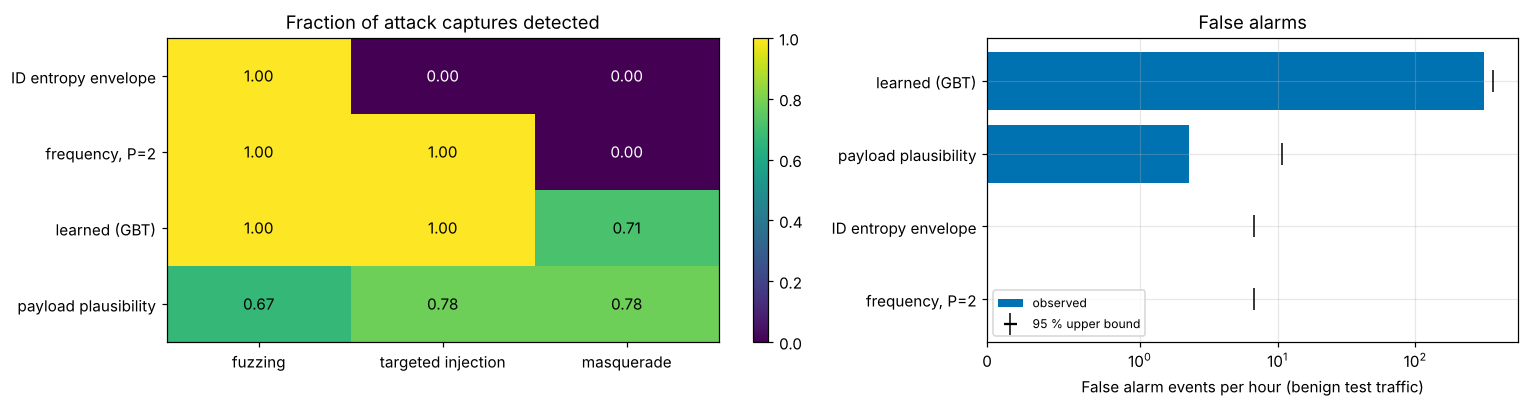

Best masquerade detection: payload plausibility (78% of captures, median delay 0 ms, 2.3 false alarms/h).


In [12]:
results = pd.concat([sm_freq, sm_ent, sm_pay, sm_ml]).reset_index()
print(results.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
piv = results.pivot(index="detector", columns="family", values="detected")[list(ATTACKS)]
ax = axes[0]
im = ax.imshow(piv.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
for (r, c), v in np.ndenumerate(piv.to_numpy()):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black")
ax.set_title("Fraction of attack captures detected"); ax.grid(False)
fig.colorbar(im, ax=ax)
ax = axes[1]
fa = results.groupby("detector", sort=False)[["fa_per_h", "fa_per_h_95up"]].first()
ax.barh(fa.index, fa.fa_per_h, color=OKABE_ITO[4], label="observed")
ax.errorbar(fa.fa_per_h_95up, fa.index, xerr=0, fmt="|", color="black", ms=14, label="95 % upper bound")
ax.set_xscale("symlog", linthresh=1); ax.set_xlabel("False alarm events per hour (benign test traffic)")
ax.set_title("False alarms"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

best_masq = results[results.family == "masquerade"].sort_values("detected", ascending=False).iloc[0]
print(f"Best masquerade detection: {best_masq.detector} ({best_masq.detected:.0%} of captures, "
      f"median delay {best_masq.median_delay_ms:.0f} ms, {best_masq.fa_per_h:.1f} false alarms/h).")

**Reading the table.** No single detector wins. Frequency rules are cheap, fast and quiet but structurally blind to a
masquerade. Entropy catches fuzzing and nothing else. Payload plausibility sees the masquerade within one frame, but only
for signals whose physics is known. The learned detector flags most attacks, including several masquerades (through
`0xFF` bytes and the transient at the start of the injection), but its false-alarm rate on unseen benign traffic would
make it unusable in a fleet. A deployed IDS therefore combines
specification-based rules per safety-relevant signal with traffic rules, and its claims are bounded by the benign data
behind its thresholds.

## 10. The masquerade beyond payload rules: clock skew, and why ROAD cannot test it

A masquerading node can forge content that *is* plausible (the reverse light). What it cannot forge easily is the
**oscillator** of the genuine ECU. Cho and Shin's CIDS (2016) estimates each identifier's clock skew from the slow drift
of arrival times and alarms when it changes. Sagong et al. (2018) showed the skew can itself be emulated.

ROAD cannot evaluate this idea fairly: its masquerade frames were created by *deleting* genuine frames next to the
injected ones, so their timing is anchored to the genuine sender, and the published timestamps were shifted during
obfuscation. The principle is therefore shown on a small synthetic arrival stream.

> **Illustrative data:** the two arrival streams below are synthetic (50 ms period, −45 ppm and −80 ppm oscillators,
> 20 µs jitter), chosen to show the principle. Note that the real jitter measured in Section 3 is about a millisecond,
> which is why CIDS-type detectors average over hundreds of frames.

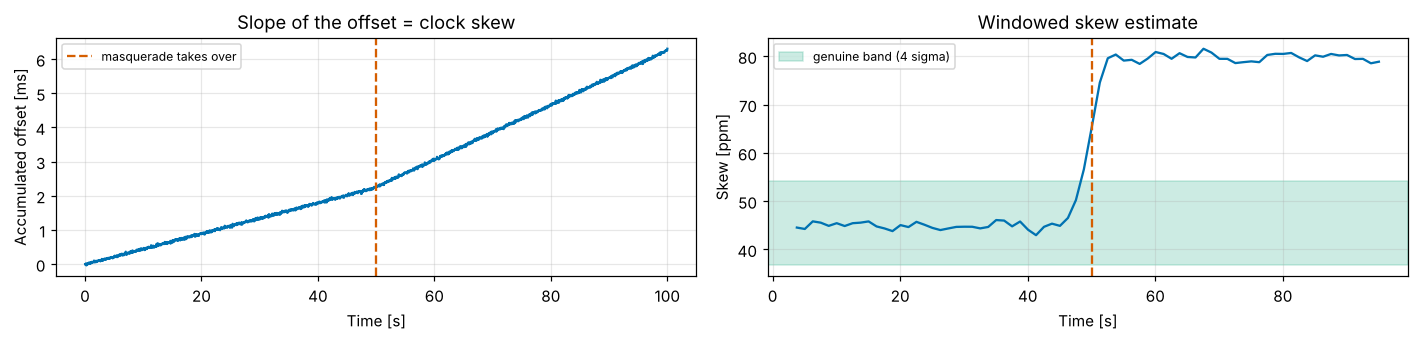

Skew step at takeover: +34 ppm, matching the 35 ppm difference between the oscillators.


In [13]:
rng_sk = np.random.default_rng(SEED)
def arrival_stream(period, skew_ppm, n, t0, jitter_s):
    step = period / (1 + skew_ppm * 1e-6)
    return t0 + np.cumsum(np.full(n, step)) + rng_sk.normal(0, jitter_s, n)

T0, n_half = 0.050, 1000
t_gen = arrival_stream(T0, -45.0, n_half, 0.0, 20e-6)            # genuine ECU
t_atk = arrival_stream(T0, -80.0, n_half, t_gen[-1], 20e-6)      # masquerading node
arr = np.concatenate([t_gen, t_atk]); k = np.arange(arr.size)
O = (arr - arr[0] - k * T0) * 1e3                                # accumulated offset [ms]

def win_skew(arr, T, window=150, step=25):
    cen, sk, kk = [], [], np.arange(window)
    for a in range(0, arr.size - window, step):
        sk.append((np.polyfit(kk, arr[a:a + window], 1)[0] / T - 1) * 1e6)
        cen.append(arr[a + window // 2])
    return np.array(cen), np.array(sk)

tc, sk = win_skew(arr, T0)
clean = tc < t_gen[-1]
mu_sk, sd_sk = sk[clean].mean(), sk[clean].std()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].plot(arr, O, color=OKABE_ITO[4]); axes[0].axvline(t_gen[-1], color=OKABE_ITO[5], ls="--", label="masquerade takes over")
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel("Accumulated offset [ms]"); axes[0].set_title("Slope of the offset = clock skew"); axes[0].legend(fontsize=8)
axes[1].plot(tc, sk, color=OKABE_ITO[4]); axes[1].axhspan(mu_sk - 4 * sd_sk, mu_sk + 4 * sd_sk, color=OKABE_ITO[2], alpha=0.2, label="genuine band (4 sigma)")
axes[1].axvline(t_gen[-1], color=OKABE_ITO[5], ls="--"); axes[1].set_xlabel("Time [s]"); axes[1].set_ylabel("Skew [ppm]")
axes[1].set_title("Windowed skew estimate"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Skew step at takeover: {sk[~clean].mean() - mu_sk:+.0f} ppm, matching the 35 ppm difference between the oscillators.")

### How an ECU is silenced: the bus-off attack

A real masquerade needs the genuine sender to fall silent (ROAD emulates this by deleting its frames). Cho & Shin (2016) describe how: the CAN error
handling that is meant to improve reliability can be turned against a node. Each controller keeps a Transmit Error
Counter (TEC). An attacker that transmits a dominant bit exactly over a victim's recessive bit — at the same moment the
victim transmits — causes a bit error; the victim increments its TEC by 8 and re-transmits, hitting the same crafted
collision again. After the TEC passes 255 the controller enters **bus-off** and stops transmitting. The model below just
illustrates the counter dynamics; it is not an attack tool.

> **Illustrative data:** the counter trajectory is a model of the ISO 11898-1 error-confinement rules, not a measurement.

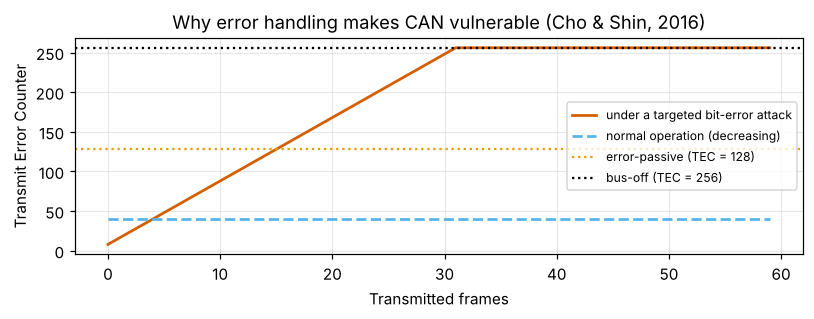

Roughly 32 forced errors (32 x 8 = 256) drive the victim into bus-off and silence it.


In [14]:
def tec_trajectory(n_frames, attacked):
    """Illustrative CAN TEC dynamics: +8 on a transmit error, -1 on a successful transmit; bus-off at 256."""
    tec = 0; traj = []
    for i in range(n_frames):
        tec += 8 if attacked else -1
        tec = max(tec, 0)
        traj.append(tec)
        if tec >= 256:                                   # error-passive at 128, bus-off at 256
            traj += [256] * (n_frames - i - 1)
            break
    return np.array(traj)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.plot(tec_trajectory(60, True), color=OKABE_ITO[5], lw=1.8, label="under a targeted bit-error attack")
ax.plot(tec_trajectory(60, False) + 40, color=OKABE_ITO[1], lw=1.8, ls="--", label="normal operation (decreasing)")
ax.axhline(128, color=OKABE_ITO[0], ls=":", label="error-passive (TEC = 128)")
ax.axhline(256, color="black", ls=":", label="bus-off (TEC = 256)")
ax.set_xlabel("Transmitted frames"); ax.set_ylabel("Transmit Error Counter")
ax.set_title("Why error handling makes CAN vulnerable (Cho & Shin, 2016)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Roughly 32 forced errors (32 x 8 = 256) drive the victim into bus-off and silence it.")

## 11. Prevention: AUTOSAR SecOC and the cost of authentication

Detection observes; **prevention** stops a forged frame from being trusted. AUTOSAR *Secure Onboard Communication*
(SecOC) appends to each protected frame a **Message Authentication Code (MAC)** over the payload plus a **freshness
value** (a monotonic counter or time), using a symmetric key shared only by the genuine sender and the receivers
(AUTOSAR CP R24-11, document 654). A masquerading ECU without the key cannot produce a valid MAC, and the freshness value
makes a replayed frame stale — closing exactly the gap — the masquerade — that detection struggled with in Sections 5–9.

The catch is **space**. A classic CAN frame has only 8 data bytes. SecOC therefore allows **truncation**: *SecOC Profile 1
(24Bit-CMAC-8Bit-FV)* uses an AES-128 CMAC truncated to the 24 most significant bits and an 8-bit truncated freshness
value — 4 bytes of overhead, leaving 4 bytes for the signal. NIST (SP 800-38B appendix) notes that a truncated MAC of
$t$ bits leaves a forgery probability of about $2^{-t}$ per attempt; 24 bits is a deliberate trade-off for a bus where
an attacker also faces arbitration and error limits. More MAC bits mean either fewer signal bytes or a second frame.

In [15]:
SECOC_PROFILES = {
    "Profile 1 (24-bit CMAC + 8-bit FV)": (3, 1),
    "Profile 3 / JASPAR (24-bit CMAC, FV elsewhere)": (3, 0),
    "Stronger (64-bit MAC + 32-bit FV, two frames)": (8, 4),
}

def secoc_overhead(mac_bytes, fv_bytes, payload_bytes=8, fd=False):
    """Frames needed and bus-time ratio when adding (MAC+FV) bytes to a payload."""
    total = payload_bytes + mac_bytes + fv_bytes
    if not fd:
        frames = int(np.ceil(total / 8))
        base = can_frame_bits(min(payload_bytes, 8))
        auth = sum(can_frame_bits(min(8, total - 8 * i)) for i in range(frames))
    else:
        frames = 1                                     # CAN FD carries up to 64 data bytes in one frame
        base = canfd_frame_bits(payload_bytes)
        auth = canfd_frame_bits(total)
    return frames, auth / base

def canfd_frame_bits(data_bytes):
    """Approximate CAN FD frame length (11-bit ID, BRS): ~29-bit arbitration phase at nominal rate +
    data phase (header ~28 bits + payload + 21-bit CRC/stuff) at the data rate; here reported in bit-times."""
    return 29 + 28 + 8 * data_bytes + 27            # simplified, enough for a relative comparison

rows = []
for name, (mac, fv) in SECOC_PROFILES.items():
    f_c, r_c = secoc_overhead(mac, fv, 8, fd=False)
    f_f, r_f = secoc_overhead(mac, fv, 8, fd=True)
    rows.append((name, mac + fv, f_c, f"{(r_c - 1) * 100:+.0f}%", f"{(r_f - 1) * 100:+.0f}%"))
over = pd.DataFrame(rows, columns=["SecOC configuration", "overhead_bytes", "classic_CAN_frames",
                                   "classic_bus_time", "CAN_FD_bus_time"])
print(over.to_string(index=False))
print("\nClassic CAN often needs a SECOND frame once 8 payload bytes are already used, roughly doubling")
print("the bus time for that message; CAN FD (up to 64 data bytes) absorbs the MAC in one frame.")

                           SecOC configuration  overhead_bytes  classic_CAN_frames classic_bus_time CAN_FD_bus_time
            Profile 1 (24-bit CMAC + 8-bit FV)               4                   2             +70%            +22%
Profile 3 / JASPAR (24-bit CMAC, FV elsewhere)               3                   2             +63%            +16%
 Stronger (64-bit MAC + 32-bit FV, two frames)              12                   3            +170%            +65%

Classic CAN often needs a SECOND frame once 8 payload bytes are already used, roughly doubling
the bus time for that message; CAN FD (up to 64 data bytes) absorbs the MAC in one frame.


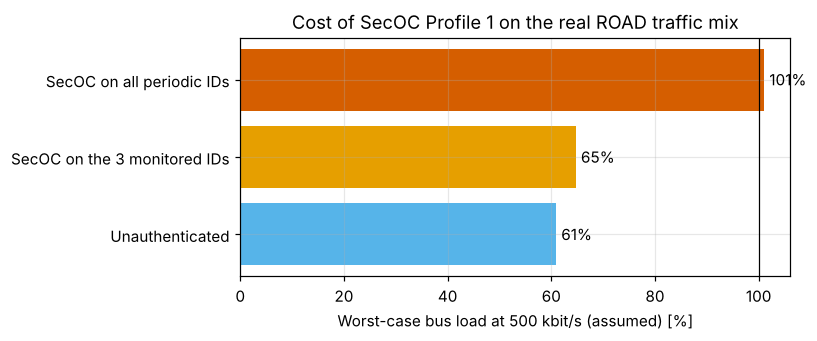

{'Unauthenticated': '61%', 'SecOC on the 3 monitored IDs': '65%', 'SecOC on all periodic IDs': '101%'}
Authenticating everything on classic CAN is not feasible on an already busy bus; SecOC is applied to the signals the TARA ranks highest, and new platforms move those to CAN FD.


In [16]:
# Bus-load impact of authenticating the periodic identifiers of the real ROAD bus (Profile 1: +4 bytes)
rates = train.groupby("can_id").size() / train.groupby("capture").t.max().sum()
dlc = train.groupby("can_id").dlc.median().astype(int)
base_bits = sum(rates[c] * can_frame_bits(dlc[c]) for c in rates.index)
def auth_bits(c):                        # 8-byte frames need a second frame; shorter ones grow by 4 bytes
    total = dlc[c] + 4
    return can_frame_bits(8) + can_frame_bits(total - 8) if total > 8 else can_frame_bits(total)
monitored = [WHEEL, SPEEDO, COOLANT]
scenarios = {"Unauthenticated": base_bits,
             "SecOC on the 3 monitored IDs": base_bits + sum(rates[c] * (auth_bits(c) - can_frame_bits(dlc[c])) for c in monitored),
             "SecOC on all periodic IDs": base_bits + sum(rates[c] * (auth_bits(c) - can_frame_bits(dlc[c])) for c in rates.index if c in PERIODIC)}
loads = {k: v / BITRATE for k, v in scenarios.items()}
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(list(loads), [100 * v for v in loads.values()], color=[OKABE_ITO[1], OKABE_ITO[0], OKABE_ITO[5]])
for i, v in enumerate(loads.values()):
    ax.text(100 * v + 1, i, f"{v:.0%}", va="center")
ax.axvline(100, color="black", lw=0.8); ax.set_xlabel(f"Worst-case bus load at {BITRATE // 1000} kbit/s (assumed) [%]")
ax.set_title("Cost of SecOC Profile 1 on the real ROAD traffic mix")
plt.tight_layout(); plt.show()
print({k: f"{v:.0%}" for k, v in loads.items()})
print("Authenticating everything on classic CAN is not feasible on an already busy bus; SecOC is applied to the"
      " signals the TARA ranks highest, and new platforms move those to CAN FD.")

Beyond per-frame authentication, defence-in-depth adds **domain gateways and segmentation** (the central gateway in the
Jeep exploit became the pivot point; segmenting the infotainment domain from the powertrain bus and filtering what may
cross is now standard), **hardware security modules** for key storage, and **secure boot / secure diagnostics** so that
the re-flashing step of that attack is itself blocked.

Looking ahead, **CAN XL** (ISO 11898-1:2024, 3rd edition) raises the payload to 2048 bytes and splits the data link layer
into LLC and MAC sublayers; its security add-on **CANsec** (CiA 613-2) reuses MACsec-style integrity, freshness,
authenticity and optional confidentiality. As of October 2026 CiA 613-2 v1.0.0 is at *draft specification proposal* stage
and member-restricted, so CANsec is best described as emerging rather than deployed.

## 12. Putting it in the standards: TARA, R155 threat list and what a reviewer asks

The ROAD attacks instantiate threat scenarios of the AEB TARA in [notebook 2](02_tara.ipynb): targeted injection and
masquerade are the classic-CAN form of **TS-01** (forged frames on the vehicle bus), fuzzing and floods the form of
**TS-07** (denial of service). UN R155 Annex 5, Part A, lists them among the threats to vehicle communication channels
(spoofing of messages, injection of untrusted data, replay, denial of service). The ratings below use the informative
attack-potential bands and risk matrix of ISO/SAE 21434 (Annexes G and H) as implemented in `avsafety.iso21434`, and add
the *detection evidence* measured in this notebook.

In [17]:
det = {f: results[results.family == f].set_index("detector").detected for f in ATTACKS}
def evidence(fam):
    d = det[fam]
    best = d.idxmax()
    return f"{best}: {d.max():.0%} of captures"
tara = pd.DataFrame([
    # ROAD attack family, 05-02 threat scenario, impact, attack-potential factors (Annex G), prevention
    # factors as for the physical attack paths AP-07a and AP-01b in 02_tara; the masquerade adds silencing the sender
    ("fuzzing", "TS-07 (DoS on the bus)", "Major", ("<=1 day", "proficient", "public", "moderate", "specialized"), "gateway filtering, rate limiting"),
    ("targeted injection", "TS-01 (forged frames)", "Severe", ("<=1 week", "proficient", "restricted", "moderate", "specialized"), "SecOC MAC + freshness"),
    ("masquerade", "TS-01 + silencing the sender", "Severe", ("<=1 month", "expert", "restricted", "moderate", "specialized"), "SecOC MAC + freshness"),
], columns=["family", "threat_scenario", "impact", "factors", "prevented_by"])
tara["attack_potential"] = [S.attack_potential(*f) for f in tara.factors]
tara["feasibility"] = tara.attack_potential.map(S.feasibility_from_potential)
tara["risk"] = [S.risk_value(i, f) for i, f in zip(tara.impact, tara.feasibility)]
tara["detection_evidence"] = tara.family.map(evidence)
print(tara.drop(columns="factors").to_string(index=False))

            family              threat_scenario impact                     prevented_by  attack_potential feasibility  risk                    detection_evidence
           fuzzing       TS-07 (DoS on the bus)  Major gateway filtering, rate limiting                11        High     4      frequency, P=2: 100% of captures
targeted injection        TS-01 (forged frames) Severe            SecOC MAC + freshness                15      Medium     4      frequency, P=2: 100% of captures
        masquerade TS-01 + silencing the sender Severe            SecOC MAC + freshness                21         Low     3 payload plausibility: 78% of captures


**What an ISO/SAE 21434 / UN R155 reviewer asks about an IDS claim** (clauses 8.3–8.4 monitoring and event evaluation,
clause 13 incident response; R155 paragraph 7.3.7 requires the manufacturer to detect and prevent attacks on the vehicle
type and to provide data forensic capability):

1. *Which threat scenarios does each rule cover, and which does it not?* Here: the masquerade is not covered by any
   traffic rule; the reverse-light masquerade by no rule at all. Uncovered scenarios must be treated by prevention or
   accepted with a rationale.
2. *On what benign data were thresholds set, and does it cover the operating conditions?* Here: 18 minutes on a
   dynamometer — the learned detector's behaviour on the on-road capture shows why that is insufficient.
3. *What are the false-alarm rate and its uncertainty?* A point estimate from minutes of data is not evidence for a fleet
   of millions of hours; the upper bound is the honest number.
4. *Is detection fast enough to matter?* Detection delay must be compared with the reaction chain (event → IdsM →
   VSOC → response) and, where the target signal is safety-relevant, with the fault-tolerant time interval of the safety
   goal (300 ms for SG-01 of the AEB example). An IDS is a monitoring control, not a safety mechanism.
5. *How were labels obtained?* Here: reconstructed from published injection intervals and payload patterns, with the
   masquerade simulated by deletion — limitations that belong in the test report.

## In industry

**Work products fed.** On-board detection supports cybersecurity monitoring and event evaluation (ISO/SAE 21434 clauses 8.3, 8.4) and incident response (clause 13); detection rules and SecOC are controls specified in the cybersecurity concept (9.5) and verified under clause 10. UN R155 (paragraph 7.3.7) requires the manufacturer to detect and prevent cyber-attacks on the vehicle type, to support its monitoring capability and to provide data forensic capability; an on-board IDS feeding a vehicle security operations centre (VSOC) is the usual way to show this. The evaluation tables of Sections 5–9 are the kind of evidence a cybersecurity verification report (clause 10.4.2) attaches to an IDS requirement.

**Owner.** In-vehicle network security engineers own the detection rules, SecOC configuration and key management; VSOC analysts triage fleet events; the PSIRT decides on response and software updates.

**Tools and formats.** Detection rules generated from the communication matrix (DBC/ARXML: periods, signal ranges, counters); security events reported through a standard interface — AUTOSAR specifies an Intrusion Detection System Manager (IdsM) that qualifies and forwards security events; a SIEM in the VSOC; key provisioning at end-of-line production and SecOC freshness management.

**Typical review findings**
- False alarms per hour stated as a point estimate from minutes of lab data, without an upper bound or on-road data.
- Learned detector validated with a random frame- or window-level split, leaking the test capture into training.
- Rules not traceable to TARA threat scenarios; no statement of which scenarios (e.g. masquerade) remain undetected.
- Security events stored without trustworthy timestamps or integrity protection, so forensic analysis is impossible.
- SecOC deployed without tested freshness resynchronisation or key update, causing frame loss that the safety concept does not cover.

**What an assessor checks:** each IDS rule and SecOC-protected signal traces to a threat scenario; detection delay and false alarms per hour measured on representative traffic with stated uncertainty; a closed loop from event to VSOC to TARA update; bus-load and timing budgets showing that security controls fit the FTTI of the affected safety goals.

## Key takeaways

1. CAN's three design properties — broadcast, priority by identifier, no sender authentication — are the root cause of every bus attack; the identifier is a *priority*, not an address.
2. Real traffic has millisecond jitter and many operating regimes; detectors tuned on idealised or narrow data look far better than they are.
3. Per-identifier frequency rules catch fuzzing and injection within one or two 100 ms windows at a low false-alarm rate, but are blind to a masquerade by construction.
4. Only content rules see a masquerade, and only where the signal's physics or context is known — which makes the communication matrix a security asset.
5. Evaluate per attack type, by capture, with detection delay and false alarms per hour **plus an upper bound**; a learned detector is only as good as the diversity of its benign data.
6. Detection does not replace prevention: SecOC closes the masquerade gap, at a bus-load cost that forces prioritisation on classic CAN and motivates CAN FD.

## Self-assessment

1. Why does the frequency detector catch the targeted injection in ROAD but not its masquerade variant?
2. The payload rules catch the speedometer masquerade but not the reverse-light masquerade. What additional information would a rule need for the reverse light?
3. A detector raised no false alarm in 27 minutes of benign test traffic. What false-alarm rate can you claim with 95 % confidence, and how much traffic would you need to claim fewer than one per 100 hours?
4. Why would a random 80/20 split of the 100 ms windows give an optimistic result for the learned detector?
5. Which ISO/SAE 21434 work products and which UN R155 requirement does the evaluation in Section 9 support?

<details>
<summary>Answers</summary>

1. Injection adds forged frames next to the genuine ones, so the identifier's frame count per window roughly doubles. In the masquerade the genuine frame before each forged one was removed, so the rate is unchanged; only the content differs.
2. Context from another signal, e.g. the gear position: "reverse light on while in Drive" is implausible, "reverse light on" alone is not. That needs the communication matrix and a cross-signal rule.
3. With zero events in $T \approx 0.44$ h, the one-sided 95 % upper bound is $3.0/T \approx 6.8$ per hour. For fewer than 0.01 per hour you need $T \geq 3.0/0.01 = 300$ hours of representative benign traffic with no false alarm.
4. Neighbouring windows of one capture are nearly identical (same drive, same attack), so windows of the same capture end up in both sets; the classifier is then tested on captures it has effectively seen.
5. Cybersecurity monitoring and event evaluation (21434 clauses 8.3, 8.4), verification of the cybersecurity controls (clause 10), incident response (clause 13); UN R155 paragraph 7.3.7 (detect and prevent attacks, monitoring capability, data forensics).
</details>

## References

Verified via Crossref, Zenodo, arXiv, USENIX, UNECE/EUR-Lex and the official standards bodies on 29 October 2026.

1. ISO 11898-1:2024, *Road vehicles — Controller area network (CAN) — Part 1: Data link layer and physical coding sublayer* (3rd ed., including CAN FD and CAN XL frame formats). https://www.iso.org/standard/86384.html
2. ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering.*
3. UNECE, *UN Regulation No. 155 — Uniform provisions concerning the approval of vehicles with regards to cyber security and cyber security management system*, Annex 5 (threat list). Official Journal of the EU, 2021. https://eur-lex.europa.eu/eli/reg/2021/387/oj
4. AUTOSAR, *Specification of Secure Onboard Communication*, Classic Platform R24-11, document 654 (SecOC profiles, truncated MAC and freshness value). https://www.autosar.org
5. M. E. Verma, R. A. Bridges, M. D. Iannacone, S. C. Hollifield, P. Moriano, S. C. Hespeler, B. Kay and F. L. Combs, *A comprehensive guide to CAN IDS data and introduction of the ROAD dataset*, PLOS ONE 19(1): e0296879, 2024. https://doi.org/10.1371/journal.pone.0296879
6. R. Bridges, M. E. Verma et al., *Real ORNL Automotive Dynamometer (ROAD) CAN Intrusion Dataset*, Zenodo, 2024, CC BY 4.0. https://doi.org/10.5281/zenodo.10462796
7. H. M. Song, J. Woo and H. K. Kim, *In-vehicle network intrusion detection using deep convolutional neural network*, Vehicular Communications 21, 2020 (HCRL Car-Hacking dataset). https://doi.org/10.1016/j.vehcom.2019.100198
8. H. M. Song, H. R. Kim and H. K. Kim, *Intrusion detection system based on the analysis of time intervals of CAN messages for in-vehicle network*, ICOIN 2016. https://doi.org/10.1109/ICOIN.2016.7427089
9. M. Müter and N. Asaj, *Entropy-based anomaly detection for in-vehicle networks*, IEEE IV 2011. https://doi.org/10.1109/IVS.2011.5940552
10. K.-T. Cho and K. G. Shin, *Fingerprinting Electronic Control Units for Vehicle Intrusion Detection*, USENIX Security 2016. https://www.usenix.org/conference/usenixsecurity16/technical-sessions/presentation/cho
11. K.-T. Cho and K. G. Shin, *Error Handling of In-vehicle Networks Makes Them Vulnerable*, ACM CCS 2016. https://doi.org/10.1145/2976749.2978302
12. S. U. Sagong, X. Ying, A. Clark, L. Bushnell and R. Poovendran, *Cloaking the Clock: Emulating Clock Skew in Controller Area Networks*, ACM/IEEE ICCPS 2018. https://doi.org/10.1109/ICCPS.2018.00012
13. C. Miller and C. Valasek, *Remote Exploitation of an Unaltered Passenger Vehicle*, IOActive white paper, 5 August 2015. https://ioactive.com/pdfs/IOActive_Remote_Car_Hacking.pdf
14. R. I. Davis, A. Burns, R. J. Bril and J. J. Lukkien, *Controller Area Network (CAN) schedulability analysis: Refuted, revisited and revised*, Real-Time Systems 35(3), 2007. https://doi.org/10.1007/s11241-007-9012-7
15. CiA 613-2, *CAN XL add-on services — Part 2: CANsec data plane* (draft specification proposal v1.0.0, 2026; member-restricted). https://www.can-cia.org/can-knowledge/cia-613-series-can-xl-add-on-services

---

**Navigation:** ← [Attack surface analysis](03_attack_surface_analysis.ipynb) · [Module index](README.md) · [V2X misbehaviour detection](05_v2x_misbehaviour_detection.ipynb) →

*Further practice:* the author's companion repository [AI-Perception-Safety-Workshop](https://github.com/milinpatel07/AI-Perception-Safety-Workshop).